In [ ]:
import sys
from pathlib import Path

# Repo layout: run this notebook from notebooks/ (or from the repo root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATASET_DIR = ROOT / "data" / "hyperview2"  # train/ and test/ folders, train_gt.csv
FIGURES_DIR = ROOT / "figures"
OUTPUTS_DIR = ROOT / "outputs"
OUTPUTS_DIR.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.feature_selection import RFE

from data_loading import load_data, BaselineRegressor

In [2]:
column_names = ['Fe', 'Zn', 'B', 'Cu', 'S', 'Mn']
n_targets = 6

## Data Loading

In [ ]:
X_train_dict, X_test_dict, y_train, n_valid_pixels_train_dict, n_valid_pixels_test_dict = load_data(reductions=['mean'], DATASET_DIR=DATASET_DIR)

X_train_hsi = np.array(X_train_dict['hsi_satellite'])
X_train_msi = np.array(X_train_dict['msi_satellite'])
X_test_hsi = np.array(X_test_dict['hsi_satellite'])
X_test_msi = np.array(X_test_dict['msi_satellite'])

In [ ]:
# Remove atmospheric water absorption bands corresponding to the 1328–1523 nm and 1812–2044 nm spectral ranges
# for all target variables except B and Mn (indices 2 and 5) - models for those target variable were performing well already
# compared to other top-performing methods
atmospheric_bands = [i for i in range(97, 115)] + [i for i in range(144, 170)]

# Remove those bands for both train and test data in version "_filtered"
X_train_hsi_filtered = np.delete(X_train_hsi, np.array(atmospheric_bands), axis=1)
X_test_hsi_filtered = np.delete(X_test_hsi, np.array(atmospheric_bands), axis=1)

In [ ]:
def transform_list(lst):
    # Calculate the new indices in the list of selected raw PRISMA bands after removing the bands affected by water absorption
    # Removal of water absorption bands was implemented after selecting the additional bands, hence this helper function
    transformed = []
    
    for num in lst:
        if num < 97:
            transformed.append(num)
        elif 97 <= num <= 115 or 144 <= num <= 170:
            continue  # drop from the list
        elif 115 < num < 144:
            transformed.append(num - 18)  # 115-97=18
        else:  # num > 170
            transformed.append(num - 44)  # 18 + 170-144 = 44

    return transformed

def append_additional_features(X_hsi, raw_hsi_bands_indices):
    # Add unprocessed HSI bands as additional features
    
    X_raw_hsi_bands = []

    for idx in raw_hsi_bands_indices:
        X_hsi_idx_arr = X_hsi[:, idx].reshape(-1, 1)
        X_raw_hsi_bands.append(X_hsi_idx_arr)
        
    return np.hstack(X_raw_hsi_bands)

In [ ]:
# Additional hyperspectral bands with high correlation to the corresponding target variable
raw_hsi_bands_indices_dict = {
    "top_features_0": [176, 219, 206, 46, 57, 0, 11, 191],
    "top_features_1": [2, 218, 143, 217, 161, 150, 191],
    "top_features_2": [0, 11, 98, 39, 78, 57, 143, 191],
    "top_features_3": [62, 76, 3, 14, 29, 40, 51, 191],
    "top_features_4": [2, 218, 143, 217, 161, 150, 191],
    "top_features_5": [0, 100, 111, 146, 161, 172, 228, 191],
}

## Data Preprocessing

In [ ]:
# Scale the Sentinel-2 data
msi_scaler = StandardScaler()
X_train_msi = msi_scaler.fit_transform(X_train_msi)
X_test_msi = msi_scaler.transform(X_test_msi)

# Apply PCA to MSI satellite data
# Testing showed benefit of PCA with 12 components
pca = PCA(n_components=12)
X_train_msi_pca = pca.fit_transform(X_train_msi)
X_test_msi_pca = pca.transform(X_test_msi)

# Apply PCA to HSI satellite data
pca = PCA(n_components=20)
X_train_hsi_pca = pca.fit_transform(X_train_hsi)
X_test_hsi_pca = pca.transform(X_test_hsi)

# Apply PCA to HSI satellite data with filtered bands
pca = PCA(n_components=20)
X_train_hsi_filtered_pca = pca.fit_transform(X_train_hsi_filtered)
X_test_hsi_filtered_pca = pca.transform(X_test_hsi_filtered)

## Recursive Feature Elimination (RFE)

In [ ]:
# Select n_best features  
best_features_indices_dict = {}

n_features_to_select_per_target = [33, 32, 30, 32, 32, 28]  # manually tuned based on the cross-validation score

for i in range(y_train.shape[1]):

    if i in [2, 5]: # B or Mn
        X_train_hsi_features = append_additional_features(X_train_hsi, raw_hsi_bands_indices_dict["top_features_"+str(i)]) 
        X_train = np.concatenate((X_train_hsi_pca, X_train_msi_pca, X_train_hsi_features), axis=1)
    else:
        transformed_list = transform_list(raw_hsi_bands_indices_dict["top_features_"+str(i)])
        X_train_hsi_features = append_additional_features(X_train_hsi_filtered, transformed_list) 
        X_train = np.concatenate((X_train_hsi_filtered_pca, X_train_msi_pca, X_train_hsi_features), axis=1)
    
    y = y_train[:, i]

    # Apply RFE with ExtraTreesRegressor
    model = ExtraTreesRegressor(n_estimators=1000, random_state=1, n_jobs=-1, max_features=0.8)
    rfe = RFE(estimator=model, n_features_to_select=n_features_to_select_per_target[i], step=1)
    fit = rfe.fit(X_train, y)

    # Get the selected features
    selected_indices = np.where(fit.support_)[0]
    selected_features = [f"feature_{idx}" for idx in selected_indices]

    #print(f"Selected features for target variable {i}: {list(selected_features)}")
    best_features_indices_dict[f'target_{i}'] = list(selected_indices)

## Hyperparmeter optimization

In [9]:
# Hyperparameter optimization on the whole training set results in a somewhat biased performance estimate.
# Performing Hparam optimization within the cross validation (CV) as nested-CV would ensure an unbiased performance estimate
# Not done here to save computational cost and iterate faster

param_grid = {
    'n_estimators': [5000],
    'max_depth': [None, 25, 30],
    'min_samples_split': [2],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [0.6, 0.75, None],
    'bootstrap': [False],
    'ccp_alpha': [0.0],
}

# Dictionary to store the best model for each target variable
best_models = {}
best_params_list = []

for i in range(n_targets):
    print(f"Optimizing hyperparameters for target variable {i+1}/{n_targets}")

    if i in [2, 5]: # B or Mn
        X_train_hsi_features = append_additional_features(X_train_hsi, raw_hsi_bands_indices_dict["top_features_"+str(i)]) 
        X_train = np.concatenate((X_train_hsi_pca, X_train_msi_pca, X_train_hsi_features), axis=1)
    else:
        transformed_list = transform_list(raw_hsi_bands_indices_dict["top_features_"+str(i)])
        X_train_hsi_features = append_additional_features(X_train_hsi_filtered, transformed_list) 
        X_train = np.concatenate((X_train_hsi_filtered_pca, X_train_msi_pca, X_train_hsi_features), axis=1)
    
    # Initialize an ExtraTreesRegressor
    rf = ExtraTreesRegressor(random_state=1, n_jobs=-1)

    # Define the search for this specific target variable
    search = GridSearchCV(
        estimator=rf,
        param_grid=param_grid,
        scoring='neg_mean_squared_error',
        cv=10,
        refit=True,
        n_jobs=-1
    )

    # Select only the optimal features for this specific target
    selected_features = best_features_indices_dict[f'target_{i}']
    X_train_selected = np.take(X_train, selected_features, axis=1)

    # Fit the grid search on training data for this target variable
    search.fit(X_train_selected, y_train[:, i])

    # Store the best model found for this target variable
    best_models[f'target_{i+1}'] = search.best_estimator_

    # Store the best parameters
    best_params_list.append(search.best_params_)
    print(f"Best parameters for target {i+1}: {search.best_params_}")

Optimizing hyperparameters for target variable 1/6
Best parameters for target 1: {'bootstrap': False, 'ccp_alpha': 0.0, 'max_depth': 25, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 5000}
Optimizing hyperparameters for target variable 2/6


/dss/dsshome1/08/di35pap/micromamba/envs/lpdaac_vitals/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters for target 2: {'bootstrap': False, 'ccp_alpha': 0.0, 'max_depth': 30, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 5000}
Optimizing hyperparameters for target variable 3/6


/dss/dsshome1/08/di35pap/micromamba/envs/lpdaac_vitals/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters for target 3: {'bootstrap': False, 'ccp_alpha': 0.0, 'max_depth': 30, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 5000}
Optimizing hyperparameters for target variable 4/6


/dss/dsshome1/08/di35pap/micromamba/envs/lpdaac_vitals/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters for target 4: {'bootstrap': False, 'ccp_alpha': 0.0, 'max_depth': 25, 'max_features': 0.75, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 5000}
Optimizing hyperparameters for target variable 5/6


/dss/dsshome1/08/di35pap/micromamba/envs/lpdaac_vitals/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters for target 5: {'bootstrap': False, 'ccp_alpha': 0.0, 'max_depth': 25, 'max_features': 0.75, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 5000}
Optimizing hyperparameters for target variable 6/6


/dss/dsshome1/08/di35pap/micromamba/envs/lpdaac_vitals/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters for target 6: {'bootstrap': False, 'ccp_alpha': 0.0, 'max_depth': 25, 'max_features': 0.6, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 5000}


## Train model on Cross Validation split of training data to evaluate performance

In [ ]:
# Cross-validation setup
n_splits = 20
kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

y_pred_val_bl_list = []
y_pred_val_rf_list = []
y_true_val_list = []

# Cross-validation loop
for i, (train_index, val_index) in enumerate(kfold.split(X_train)):
    print(f"CV fold {i+1}/{n_splits}")
    # Fit the baseline model
    baseline_reg = BaselineRegressor()
    baseline_reg.fit(None, y_train[train_index])
    y_pred_val_baseline = baseline_reg.predict(X_train[val_index])
    y_pred_val_bl_list.append(y_pred_val_baseline)

    # Train one model for each target variable
    for k in range(n_targets):
        rf_best_params = best_params_list[k]
        rf = ExtraTreesRegressor(**rf_best_params, n_jobs=-1, random_state=1)

        if k in [2, 5]: # B or Mn
            X_train_hsi_features = append_additional_features(X_train_hsi, raw_hsi_bands_indices_dict["top_features_"+str(k)]) 
            X_train = np.concatenate((X_train_hsi_pca, X_train_msi_pca, X_train_hsi_features), axis=1)
        else:
            transformed_list = transform_list(raw_hsi_bands_indices_dict["top_features_"+str(k)])
            X_train_hsi_features = append_additional_features(X_train_hsi_filtered, transformed_list) 
            X_train = np.concatenate((X_train_hsi_filtered_pca, X_train_msi_pca, X_train_hsi_features), axis=1)
        
        # Select the optimal features for this target variable
        selected_features = best_features_indices_dict[f'target_{k}']
        X_train_selected = np.take(X_train, selected_features, axis=1)
        rf.fit(X_train_selected[train_index], y_train[train_index, k])
        
        y_pred_val_rf = rf.predict(X_train_selected[val_index])
        if k == 0:
            y_pred_val_rf_list.append(y_pred_val_rf.reshape(-1, 1))
        else:
            y_pred_val_rf_list[-1] = np.hstack((y_pred_val_rf_list[-1], y_pred_val_rf.reshape(-1, 1)))

    # Store the validation targets
    y_true_val_list.append(y_train[val_index])

In [11]:
# Evaluate performance on out-of-fold sets
# These performance estimates are expected to be worse than on the test set as the models are not trained on the whole training set
final_scores = []

scores_targets = np.zeros((1, 6))

for y_pred_val_bl, y_pred_val_rf, y_true_val in zip(y_pred_val_bl_list, y_pred_val_rf_list, y_true_val_list):

    mse_rf = np.mean((y_true_val - y_pred_val_rf) ** 2, axis=0)
    mse_bl = np.mean((y_true_val - y_pred_val_bl) ** 2, axis=0)

    # Calculate the score for each class individually
    scores = mse_rf / mse_bl

    scores_targets = scores_targets + scores

    # Calculate the final score (mean of target variables)
    final_score = np.mean(scores)
    final_scores.append(final_score)

scores_targets /= n_splits

for score, class_name in zip(scores_targets.flatten(), column_names):
    print(f"Target variable {class_name} score: {round(score, 4)}")

final_score = np.sum(final_scores) / n_splits

print(f"Final score: {round(final_score, 4)}")

Target variable Fe score: 0.3479
Target variable Zn score: 0.3433
Target variable B score: 0.2857
Target variable Cu score: 0.5057
Target variable S score: 0.5205
Target variable Mn score: 0.3723
Final score: 0.3959


## Use models trained on whole train data & prepare submission

In [12]:
column_names = ['Fe', 'Zn', 'B', 'Cu', 'S', 'Mn']
y_pred_test_list = []

for i, column_name in enumerate(column_names):
    best_model = best_models[f'target_{i+1}']

    if i in [2, 5]: # B or Mn
        X_test_hsi_features = append_additional_features(X_test_hsi, raw_hsi_bands_indices_dict["top_features_"+str(i)]) 
        X_test = np.concatenate((X_test_hsi_pca, X_test_msi_pca, X_test_hsi_features), axis=1)
    else:
        transformed_list = transform_list(raw_hsi_bands_indices_dict["top_features_"+str(i)])
        X_test_hsi_features = append_additional_features(X_test_hsi_filtered, transformed_list) 
        X_test = np.concatenate((X_test_hsi_filtered_pca, X_test_msi_pca, X_test_hsi_features), axis=1)

    # Select only the optimal features for this specific target
    selected_features = best_features_indices_dict[f'target_{i}']
    X_test_selected = np.take(X_test, selected_features, axis=1)
    y_pred_test = best_model.predict(X_test_selected)
    y_pred_test_list.append(y_pred_test)

# Create the DataFrame with all predictions
submission = pd.DataFrame(data=y_pred_test_list).T
submission.columns = column_names

# Save to CSV
submission.to_csv(OUTPUTS_DIR / "submission.csv", index_label="sample_index")

## Understanding the results

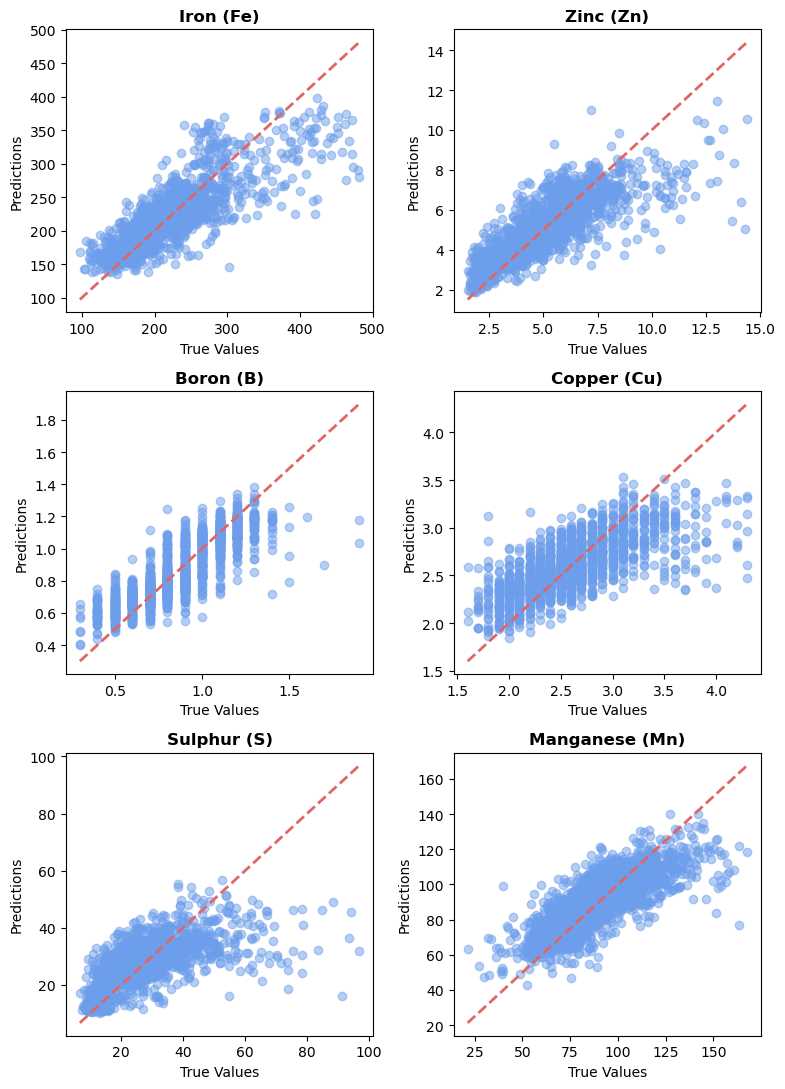

In [16]:
column_names = ['Iron (Fe)', 'Zinc (Zn)', 'Boron (B)', 'Copper (Cu)', 'Sulphur (S)', 'Manganese (Mn)']

# Convert lists to numpy arrays
y_pred_val_rf_array = np.vstack(y_pred_val_rf_list)
y_true_val_array = np.vstack(y_true_val_list)

# Create a 2x3 grid of subplots
fig, axes = plt.subplots(3, 2, figsize=(8, 11))  # Adjust figsize as needed

# Flatten axes array for easy iteration (if n_targets > 6, handle dynamically)
axes = axes.flatten()

for j in range(n_targets):
    # Plot scatter and diagonal line
    scatter_plot = axes[j].scatter(
        y_true_val_array[:, j],
        y_pred_val_rf_array[:, j],
        alpha=0.5,
        color='#6D9EEB'
    )
    axes[j].plot(
        [y_true_val_array[:, j].min(), y_true_val_array[:, j].max()],
        [y_true_val_array[:, j].min(), y_true_val_array[:, j].max()],
        color='#E06666',  # Custom hex color
        linestyle='--',
        linewidth=2
    )

    # Set labels and title
    axes[j].set_xlabel('True Values', fontsize=10)
    axes[j].set_ylabel('Predictions', fontsize=10)
    axes[j].set_title(f'{column_names[j]}', fontsize=12, fontweight='bold')

# Hide unused subplots (if n_targets < 6)
for k in range(n_targets, len(axes)):
    axes[k].axis('off')

plt.tight_layout()#rect=[0, 0.03, 1, 0.95])  # Adjust layout to prevent overlap
plt.savefig(FIGURES_DIR / "train_predictions_vs_truth.png", dpi=300)
plt.show()

In [ ]:
# Calculate metrics for each target variable
metrics_results = []

print("Metrics for each target variable:")
print("-" * 50)

for j in range(n_targets):
    # Extract true and predicted values for current target
    y_true = y_true_val_array[:, j]
    y_pred = y_pred_val_rf_array[:, j]
    
    # Calculate metrics
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    # Store results
    metrics_results.append({
        'target': column_names[j],
        'MSE': mse,
        'MAE': mae,
        'R2': r2
    })
    
    print(f"{column_names[j]}:")
    print(f"  MSE: {mse:.6f}")
    print(f"  MAE: {mae:.6f}")
    print(f"  R2:  {r2:.6f}")
    print()

# Create DataFrame for LaTeX table
results_df = pd.DataFrame(metrics_results)
results_df = results_df.rename(columns={'target': 'Target', 'MSE': 'MSE', 'MAE': 'MAE', 'R2': 'R²'})

# Generate LaTeX table
latex_table = results_df.to_latex(caption="Model Performance Metrics for Each Target Variable", 
                                  label="tab:model_metrics",
                                  index=False,
                                  float_format="{:.6f}".format)

print("\n" + "="*60)
print("LATEX TABLE")
print("="*60)
print(latex_table)

# Also save to file
with open(OUTPUTS_DIR / 'metrics_table.tex', 'w') as f:
    f.write(latex_table)

print("\nLaTeX table saved to 'metrics_table.tex'")

Metrics for each target variable:
--------------------------------------------------
Iron (Fe):
  MSE: 1172.466636
  MAE: 23.714830
  R2:  0.666397

Zinc (Zn):
  MSE: 1.433113
  MAE: 0.824996
  R2:  0.652752

Boron (B):
  MSE: 0.015601
  MAE: 0.093538
  R2:  0.716411

Copper (Cu):
  MSE: 0.105207
  MAE: 0.236196
  R2:  0.490253

Sulphur (S):
  MSE: 87.923522
  MAE: 6.227150
  R2:  0.471882

Manganese (Mn):
  MSE: 175.850754
  MAE: 9.849083
  R2:  0.626863


LATEX TABLE
\begin{table}
\caption{Model Performance Metrics for Each Target Variable}
\label{tab:model_metrics}
\begin{tabular}{lrrr}
\toprule
Target & MSE & MAE & R² \\
\midrule
Iron (Fe) & 1172.466636 & 23.714830 & 0.666397 \\
Zinc (Zn) & 1.433113 & 0.824996 & 0.652752 \\
Boron (B) & 0.015601 & 0.093538 & 0.716411 \\
Copper (Cu) & 0.105207 & 0.236196 & 0.490253 \\
Sulphur (S) & 87.923522 & 6.227150 & 0.471882 \\
Manganese (Mn) & 175.850754 & 9.849083 & 0.626863 \\
\bottomrule
\end{tabular}
\end{table}


LaTeX table saved to 'metr